# Experiment 3: topology rewiring

**Question.** Keep the rule (Conway's B3/S23) and the number of neighbours (8) fixed, and change only *who* is whose neighbour. Starting from a 64 × 64 torus, a fraction $\beta$ of the edges is rewired at random: $\beta = 0$ is the lattice, small $\beta$ gives a *small-world* network, and $\beta = 1$ a random 8-regular network. How do structure, transients, final states and damage spreading change with $\beta$?

Rewiring uses degree-preserving double-edge swaps (`life.networks.rewire`), so every node keeps exactly 8 neighbours. Classic Watts–Strogatz rewiring, which lets degrees vary, is run as a comparison in part 3d.

| Symbol | Meaning |
|---|---|
| $\ell$ | mean shortest-path length: how many hops apart two nodes are on average |
| $C$ | clustering: the chance that two neighbours of a node are also neighbours of each other |

## Predictions (written before any run)

| # | Question | Prediction |
|---|---|---|
| 1 | Which falls first as $\beta$ grows, $\ell$ or $C$? At what $\beta$ is $\ell$ halved? | $C$ falls first; $\ell$ is halved around $\beta \approx 0.1$ |
| 2 | Transient at $\beta = 1$ vs. the lattice (median ≈ 1000) | longer, by about 100 generations |
| 3 | Runs that do not settle within 20 000 generations? | yes; unsure at which $\beta$ |
| 4 | What is left at $\beta = 1$? | still patterns |
| 5 | Period-$4L$ gliders at $\beta = 0.01$? Most common period at $\beta = 1$? | no gliders; period about 100 |
| 6 | Damage on a small world ($\beta = 0.03$) vs. the lattice; same-attractor fraction | spreads more slowly; fraction unchanged |
| 7 | An abrupt change in the dynamics? Does it line up with the fall of $\ell$ or of $C$? | yes, with the fall of $C$ |

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from life.metrics import damage_spread, detect_cycle, flip
from life.networks import clustering, mean_path_length, rewire, watts_strogatz
from life.rules import CONWAY
from life.topology import Graph, lattice_adjacency

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
DATA = ROOT / "data" / "exp03"
FIGURES.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

SIZE = 64
N = SIZE * SIZE
DENSITY = 0.35
MAX_STEPS = 20_000
RUNS = 50
BETAS = [0.0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
LATTICE = lattice_adjacency((SIZE, SIZE), "torus")


def network(beta, seed, method="rewire"):
    rng = np.random.default_rng([int(beta * 1e6), seed, 7])
    build = rewire if method == "rewire" else watts_strogatz
    return build(LATTICE, beta, rng)


def soup(seed):
    return np.random.default_rng(20_000 + seed).random((SIZE, SIZE)) < DENSITY


def final_density(cycle):
    return np.unpackbits(np.frombuffer(cycle.attractor, dtype=np.uint8))[:N].mean()

## 3a. Structure: clustering and path length

Five networks per $\beta$; $\ell$ is estimated from 200 random source nodes. Values are shown relative to the lattice ($\beta = 0$).

In [2]:
structure = []
for beta in BETAS:
    for seed in range(5):
        a = network(beta, seed)
        rng = np.random.default_rng(seed)
        structure.append((beta, seed, clustering(a), mean_path_length(a, 200, rng)))
structure = np.array(structure)
np.savetxt(
    DATA / "structure.csv",
    structure,
    delimiter=",",
    fmt="%.6g",
    header="beta,seed,clustering,path_length",
    comments="",
)

c0 = structure[structure[:, 0] == 0, 2].mean()
l0 = structure[structure[:, 0] == 0, 3].mean()
print(f"lattice: C = {c0:.3f}, l = {l0:.2f}")
print(f"{'beta':>6} {'C/C0':>7} {'l/l0':>7}")
for beta in BETAS:
    rows = structure[structure[:, 0] == beta]
    print(f"{beta:>6} {rows[:, 2].mean() / c0:>7.3f} {rows[:, 3].mean() / l0:>7.3f}")

lattice: C = 0.429, l = 21.34
  beta    C/C0    l/l0
   0.0   1.000   1.000
 0.001   0.997   0.776
 0.003   0.991   0.601
  0.01   0.970   0.458
  0.03   0.914   0.355
   0.1   0.729   0.273
   0.3   0.344   0.223
   1.0   0.004   0.203


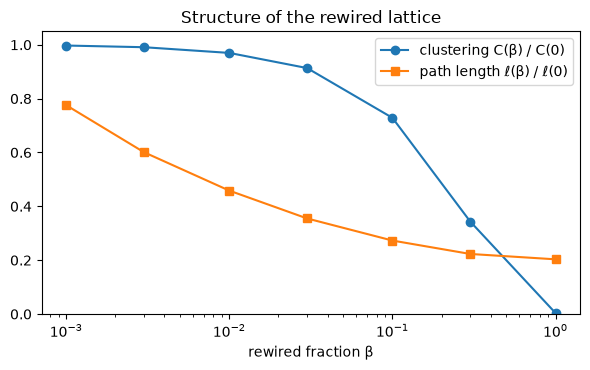

In [3]:
betas_pos = np.array(BETAS[1:])
c_rel = [structure[structure[:, 0] == b, 2].mean() / c0 for b in betas_pos]
l_rel = [structure[structure[:, 0] == b, 3].mean() / l0 for b in betas_pos]

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.semilogx(betas_pos, c_rel, "o-", label="clustering C(β) / C(0)")
ax.semilogx(betas_pos, l_rel, "s-", label="path length ℓ(β) / ℓ(0)")
ax.set_xlabel("rewired fraction β")
ax.set_ylim(0, 1.05)
ax.set_title("Structure of the rewired lattice")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "exp03_structure.png", dpi=150)
plt.show()

## 3b. Dynamics: transients, periods, final states

For each $\beta$: 50 runs, each on a freshly rewired network with its own random soup (density 0.35), followed to its cycle (cap 20 000 generations). The final live density is read from a state on the cycle.

In [4]:
records = []  # beta, seed, transient, period, final density; -1 marks a censored run
for beta in BETAS:
    start = time.perf_counter()
    for seed in range(RUNS):
        cycle = detect_cycle(soup(seed), CONWAY, Graph(network(beta, seed)), MAX_STEPS)
        if cycle is None:
            records.append((beta, seed, -1, -1, -1.0))
        else:
            records.append((beta, seed, cycle.transient, cycle.period, final_density(cycle)))
    print(f"beta = {beta:<6}: {RUNS} runs in {time.perf_counter() - start:.1f} s")

dyn = np.array(records)
np.savetxt(
    DATA / "dynamics.csv",
    dyn,
    delimiter=",",
    fmt="%.6g",
    header="beta,seed,transient,period,final_density",
    comments="",
)

beta = 0.0   : 50 runs in 5.9 s
beta = 0.001 : 50 runs in 4.1 s
beta = 0.003 : 50 runs in 3.2 s
beta = 0.01  : 50 runs in 2.4 s
beta = 0.03  : 50 runs in 2.8 s
beta = 0.1   : 50 runs in 5.6 s
beta = 0.3   : 50 runs in 77.2 s
beta = 1.0   : 50 runs in 108.5 s


In [5]:
def summary(table, beta):
    rows = table[table[:, 0] == beta]
    done = rows[rows[:, 2] >= 0]
    censored = int(np.sum(rows[:, 2] < 0))
    if len(done) == 0:
        return censored, np.nan, np.nan, np.nan, ""
    periods, counts = np.unique(done[:, 3].astype(int), return_counts=True)
    order = np.argsort(-counts)[:4]
    top = ", ".join(f"{periods[i]}×{counts[i]}" for i in order)
    return (
        censored,
        np.median(done[:, 2]),
        np.percentile(done[:, 2], 90),
        np.median(done[:, 4]),
        top,
    )


print(f"{'beta':>6} {'cens.':>6} {'median T':>9} {'p90 T':>7} {'density':>8}  periods")
for beta in BETAS:
    cens, med, p90, dens, top = summary(dyn, beta)
    print(f"{beta:>6} {cens:>6} {med:>9.0f} {p90:>7.0f} {dens:>8.3f}  {top}")

  beta  cens.  median T   p90 T  density  periods
   0.0      0      1124    2751    0.030  2×50
 0.001      0       878    1614    0.028  2×49, 256×1
 0.003      0       626    1201    0.026  2×50
  0.01      0       320     510    0.024  2×49, 1×1
  0.03      0       172     230    0.020  2×46, 1×4
   0.1      0        98     111    0.015  2×29, 1×19, 4×1, 6×1
   0.3     50       nan     nan      nan  
   1.0     50       nan     nan      nan  


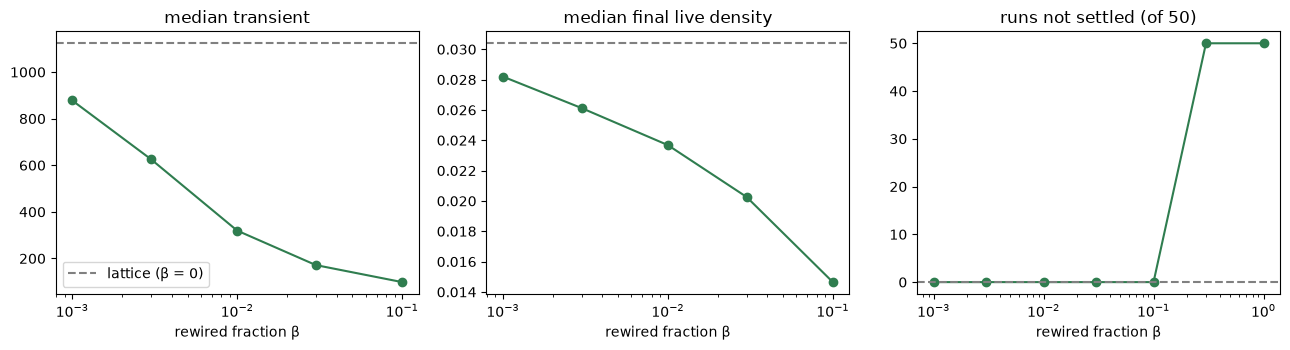

In [6]:
x = np.array(BETAS[1:])
stats = np.array([summary(dyn, b)[:4] for b in BETAS], dtype=float)
lattice = stats[0]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
panels = [
    (1, "median transient"),
    (3, "median final live density"),
    (0, "runs not settled (of 50)"),
]
for ax, (col, label) in zip(axes, panels, strict=True):
    ax.semilogx(x, stats[1:, col], "o-", color="#2f7d4f")
    ax.axhline(lattice[col], color="grey", ls="--", label="lattice (β = 0)")
    ax.set_xlabel("rewired fraction β")
    ax.set_title(label)
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "exp03_dynamics.png", dpi=150)
plt.show()

## 3c. Damage spreading on three topologies

50 pairs per $\beta$ (lattice, small world, random), one random cell flipped, 1500 generations. Each pair runs on its own network. For pairs that settle, the final attractors are compared.

In [7]:
DAMAGE_BETAS = [0.0, 0.03, 1.0]
DAMAGE_RUNS = 50
DAMAGE_STEPS = 1500

damage = {}
attractors = {}
for beta in DAMAGE_BETAS:
    start = time.perf_counter()
    curves, same, differ, censored = [], 0, 0, 0
    for seed in range(DAMAGE_RUNS):
        g = Graph(network(beta, 100 + seed))
        s = soup(100 + seed)
        cell = tuple(int(v) for v in np.random.default_rng(30_000 + seed).integers(0, SIZE, 2))
        curves.append(damage_spread(s, cell, DAMAGE_STEPS, CONWAY, g))
        a = detect_cycle(s, CONWAY, g, MAX_STEPS)
        b = detect_cycle(flip(s, cell), CONWAY, g, MAX_STEPS)
        if a is None or b is None:
            censored += 1
        elif a.attractor == b.attractor:
            same += 1
        else:
            differ += 1
    damage[f"beta_{beta}"] = np.array(curves)
    attractors[beta] = (same, differ, censored)
    print(f"beta = {beta:<5}: {time.perf_counter() - start:.1f} s")

np.savez_compressed(DATA / "damage.npz", **damage)
print()
print(f"{'beta':>6} {'healed':>7} {'peak d/N':>9} {'at t':>5} {'end d/N':>8}  same/differ/censored")
for beta in DAMAGE_BETAS:
    d = damage[f"beta_{beta}"]
    med = np.median(d, axis=0) / N
    same, differ, censored = attractors[beta]
    print(
        f"{beta:>6} {np.mean(d[:, -1] == 0):>7.0%} {med.max():>9.3f} {med.argmax():>5} "
        f"{med[-1]:>8.3f}  {same}/{differ}/{censored}"
    )

beta = 0.0  : 17.3 s
beta = 0.03 : 12.9 s
beta = 1.0  : 195.3 s

  beta  healed  peak d/N  at t  end d/N  same/differ/censored
   0.0      0%     0.173    87    0.063  0/50/0
  0.03      0%     0.290    19    0.042  0/50/0
   1.0      0%     0.473   769    0.468  0/0/50


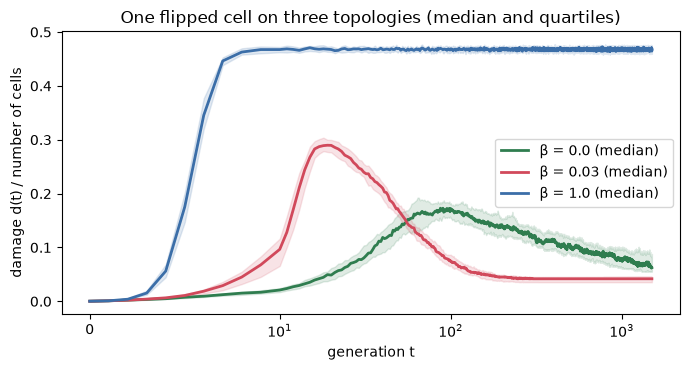

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
t = np.arange(DAMAGE_STEPS + 1)
for beta, color in zip(DAMAGE_BETAS, ["#2f7d4f", "#d1495b", "#3b6ea8"], strict=True):
    d = damage[f"beta_{beta}"] / N
    ax.plot(t, np.median(d, axis=0), color=color, lw=2, label=f"β = {beta} (median)")
    ax.fill_between(t, *np.percentile(d, [25, 75], axis=0), color=color, alpha=0.15)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlabel("generation t")
ax.set_ylabel("damage d(t) / number of cells")
ax.set_title("One flipped cell on three topologies (median and quartiles)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "exp03_damage.png", dpi=150)
plt.show()

## 3d. Comparison: classic Watts–Strogatz (degrees not preserved)

Same soups and seeds as 3b, but rewired with `watts_strogatz`, so nodes end up with different numbers of neighbours.

In [9]:
WS_BETAS = [0.01, 0.1, 1.0]
ws = []
for beta in WS_BETAS:
    start = time.perf_counter()
    for seed in range(RUNS):
        g = Graph(network(beta, seed, method="ws"))
        cycle = detect_cycle(soup(seed), CONWAY, g, MAX_STEPS)
        if cycle is None:
            ws.append((beta, seed, -1, -1, -1.0))
        else:
            ws.append((beta, seed, cycle.transient, cycle.period, final_density(cycle)))
    print(f"WS beta = {beta:<5}: {time.perf_counter() - start:.1f} s")
ws = np.array(ws)
np.savetxt(
    DATA / "watts_strogatz.csv",
    ws,
    delimiter=",",
    fmt="%.6g",
    header="beta,seed,transient,period,final_density",
    comments="",
)

print()
print(f"{'beta':>6} {'method':>18} {'cens.':>6} {'median T':>9} {'density':>8}  periods")
for beta in WS_BETAS:
    for name, table in [("degree-preserving", dyn), ("Watts-Strogatz", ws)]:
        cens, med, _, dens, top = summary(table, beta)
        print(f"{beta:>6} {name:>18} {cens:>6} {med:>9.0f} {dens:>8.3f}  {top}")

WS beta = 0.01 : 3.4 s
WS beta = 0.1  : 2.8 s
WS beta = 1.0  : 90.5 s

  beta             method  cens.  median T  density  periods
  0.01  degree-preserving      0       320    0.024  2×49, 1×1
  0.01     Watts-Strogatz      0       349    0.024  2×50
   0.1  degree-preserving      0        98    0.015  2×29, 1×19, 4×1, 6×1
   0.1     Watts-Strogatz      0       100    0.013  1×27, 2×23
   1.0  degree-preserving     50       nan      nan  
   1.0     Watts-Strogatz     50       nan      nan  


## 3e. Where exactly does the dynamics switch?

Part 3b showed that every run settles at $\beta = 0.1$ and none does at $\beta = 0.3$. This part sweeps the gap (30 runs per $\beta$) and puts the fraction of runs that never settle next to the clustering of the same networks.

In [10]:
FINE_BETAS = [0.12, 0.15, 0.18, 0.2, 0.22, 0.25]
FINE_RUNS = 30

fine = []
for beta in FINE_BETAS:
    start = time.perf_counter()
    for seed in range(FINE_RUNS):
        cycle = detect_cycle(soup(seed), CONWAY, Graph(network(beta, seed)), MAX_STEPS)
        if cycle is None:
            fine.append((beta, seed, -1, -1, -1.0))
        else:
            fine.append((beta, seed, cycle.transient, cycle.period, final_density(cycle)))
    print(f"beta = {beta:<5}: {FINE_RUNS} runs in {time.perf_counter() - start:.1f} s")
fine = np.array(fine)
np.savetxt(
    DATA / "transition.csv",
    fine,
    delimiter=",",
    fmt="%.6g",
    header="beta,seed,transient,period,final_density",
    comments="",
)

sweep = sorted(set(BETAS) | set(FINE_BETAS))
rows_all = np.vstack([dyn, fine])
print()
print(f"{'beta':>6} {'runs':>5} {'not settled':>12} {'median T (settled)':>19} {'C/C0':>6}")
transition = []
for beta in sweep:
    rows = rows_all[rows_all[:, 0] == beta]
    done = rows[rows[:, 2] >= 0]
    frac = np.mean(rows[:, 2] < 0)
    c_rel = np.mean([clustering(network(beta, s)) for s in range(3)]) / c0
    med = np.median(done[:, 2]) if len(done) else np.nan
    transition.append((beta, frac, c_rel))
    print(f"{beta:>6} {len(rows):>5} {frac:>12.0%} {med:>19.0f} {c_rel:>6.3f}")
transition = np.array(transition)

beta = 0.12 : 30 runs in 4.2 s
beta = 0.15 : 30 runs in 5.0 s
beta = 0.18 : 30 runs in 6.5 s
beta = 0.2  : 30 runs in 25.5 s
beta = 0.22 : 30 runs in 44.8 s
beta = 0.25 : 30 runs in 45.1 s

  beta  runs  not settled  median T (settled)   C/C0
   0.0    50           0%                1124  1.000
 0.001    50           0%                 878  0.997
 0.003    50           0%                 626  0.991
  0.01    50           0%                 320  0.970
  0.03    50           0%                 172  0.913
   0.1    50           0%                  98  0.728
  0.12    30           0%                 101  0.681
  0.15    30           0%                 118  0.614
  0.18    30           0%                 188  0.554
   0.2    30          17%                7054  0.511
  0.22    30         100%                 nan  0.475
  0.25    30         100%                 nan  0.423
   0.3    50         100%                 nan  0.344
   1.0    50         100%                 nan  0.004


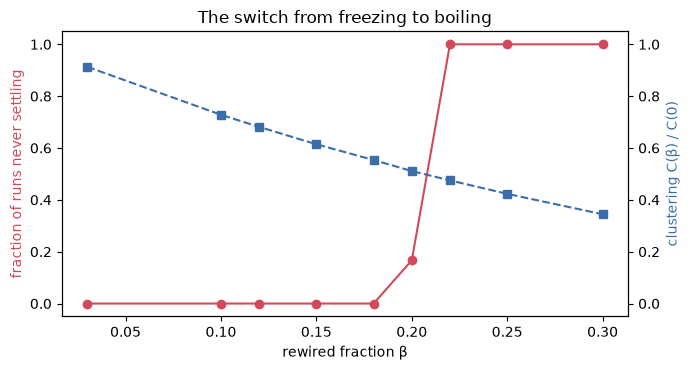

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
mask = (transition[:, 0] >= 0.03) & (transition[:, 0] <= 0.5)
ax.plot(
    transition[mask, 0], transition[mask, 1], "o-", color="#d1495b", label="runs never settling"
)
ax.set_xlabel("rewired fraction β")
ax.set_ylabel("fraction of runs never settling", color="#d1495b")
ax.set_ylim(-0.05, 1.05)
twin = ax.twinx()
twin.plot(transition[mask, 0], transition[mask, 2], "s--", color="#3b6ea8", label="clustering C/C0")
twin.set_ylabel("clustering C(β) / C(0)", color="#3b6ea8")
twin.set_ylim(-0.05, 1.05)
ax.set_title("The switch from freezing to boiling")
fig.tight_layout()
fig.savefig(FIGURES / "exp03_transition.png", dpi=150)
plt.show()

### Mean-field check on the random network ($\beta = 1$)

If neighbours were independent, each alive with probability $\rho$, one step of B3/S23 would map $\rho$ to

$$f(\rho) = \rho\,[P(2) + P(3)] + (1-\rho)\,P(3), \qquad P(k) = \binom{8}{k}\rho^k(1-\rho)^{8-k}.$$

Its fixed points $f(\rho) = \rho$ predict where a boiling network settles, and below which starting density activity should die out. Here the prediction is compared with runs on random 8-regular networks started at different densities (10 runs each, 3000 generations).

In [12]:
from math import comb


def mean_field(r):
    p = lambda k: comb(8, k) * r**k * (1 - r) ** (8 - k)  # noqa: E731
    return r * (p(2) + p(3)) + (1 - r) * p(3)


grid = np.linspace(0.001, 0.999, 99_801)
gap = np.array([mean_field(r) - r for r in grid])
roots = grid[np.flatnonzero(np.diff(np.sign(gap)))]
print("mean-field fixed points (besides 0):", ", ".join(f"{r:.3f}" for r in roots))

from life.engine import run  # noqa: E402

START_DENSITIES = [0.05, 0.1, 0.15, 0.2, 0.35]
mf = []
for rho0 in START_DENSITIES:
    for seed in range(10):
        g = Graph(network(1.0, 500 + seed))
        state = np.random.default_rng(40_000 + seed).random((SIZE, SIZE)) < rho0
        history = run(state, 3000, CONWAY, g)
        mf.append((rho0, seed, history[-500:].mean()))
mf = np.array(mf)
np.savetxt(
    DATA / "mean_field.csv",
    mf,
    delimiter=",",
    fmt="%.6g",
    header="start_density,seed,late_density",
    comments="",
)
print()
print(f"{'start':>6} {'died out':>9} {'late density (alive runs)':>26}")
for rho0 in START_DENSITIES:
    rows = mf[mf[:, 0] == rho0]
    alive = rows[rows[:, 2] > 0.05]
    late = np.median(alive[:, 2]) if len(alive) else np.nan
    print(f"{rho0:>6} {np.sum(rows[:, 2] <= 0.05):>6}/10 {late:>26.3f}")

mean-field fixed points (besides 0): 0.192, 0.370

 start  died out  late density (alive runs)
  0.05     10/10                        nan
   0.1     10/10                        nan
  0.15     10/10                        nan
   0.2      6/10                      0.373
  0.35      0/10                      0.373


## Side by side: the same soup on the lattice and on a small world

Left: $\beta = 0$. Right: $\beta = 0.01$ (1 % of edges rewired). Cells are drawn at their lattice positions in both panels; on the right, a few of them have neighbours far away.

In [13]:
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap

from life.engine import run

frames = 240
start_state = soup(0)
left = run(start_state, frames, CONWAY, Graph(LATTICE))
right = run(start_state, frames, CONWAY, Graph(network(0.01, 0)))

cmap = ListedColormap(["#f4f5f6", "#2f7d4f"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4.6, 2.6), dpi=70)
im1 = ax1.imshow(left[0], cmap=cmap, vmin=0, vmax=1)
im2 = ax2.imshow(right[0], cmap=cmap, vmin=0, vmax=1)
for ax in (ax1, ax2):
    ax.set_xticks([])
    ax.set_yticks([])
t1 = ax1.set_title(f"lattice · t = {frames}", fontsize=8)
t2 = ax2.set_title(f"β = 0.01 · t = {frames}", fontsize=8)
fig.tight_layout()


def update(i):
    im1.set_data(left[i])
    im2.set_data(right[i])
    t1.set_text(f"lattice · t = {i}")
    t2.set_text(f"β = 0.01 · t = {i}")
    return im1, im2, t1, t2


animation = FuncAnimation(fig, update, frames=range(0, frames + 1, 6))
out = FIGURES / "exp03_side_by_side.gif"
animation.save(out, writer=PillowWriter(fps=8))
plt.close(fig)
print(f"saved {out.name}: {out.stat().st_size / 1e6:.2f} MB")

saved exp03_side_by_side.gif: 0.62 MB


## Results vs. predictions

| # | Prediction | Result |
|---|---|---|
| 1 | $C$ falls first; $\ell$ halved at $\beta \approx 0.1$ | Reversed: $\ell$ falls first and is halved near $\beta$ = 0.01, while $C$ barely moves until 0.1. This gap is exactly what a small world is. |
| 2 | slightly longer transients at $\beta = 1$ | Right direction, wrong scale: the runs never settle at all. |
| 3 | some runs never settle | Correct, and it is all or nothing: none up to $\beta$ = 0.18, all from 0.22. |
| 4 | still patterns at $\beta = 1$ | Wrong: the network keeps boiling at density 0.37 (puzzle B). |
| 5 | no gliders at $\beta = 0.01$ | Correct for 0.01 (although one glider survived at 0.001, puzzle D). The question about periods at $\beta = 1$ does not apply: there are no cycles. |
| 6 | damage spreads more slowly on a small world; same-attractor fraction unchanged | First half wrong: it spreads faster and higher (puzzle E). Second half correct: 0 of 50 on both. |
| 7 | the switch lines up with the fall of $C$ | **Correct.** The switch at $\beta \approx 0.2$ happens while $C$ is falling through half its lattice value; $\ell$ had already done most of its falling by $\beta$ = 0.01. |

## Puzzles

The data did a few things that were not obvious in advance. Try each one before opening the answer.

**A. The switch from freezing to boiling happens where clustering has halved, not where distances shrink.**
*Hint: a block is four cells that are all neighbours of each other. What does that look like in a network?*

<details><summary>Answer (a hypothesis)</summary>

A soup freezes by turning into still lifes and blinkers, and these depend on tightly knit groups of neighbours: a block is a 4-clique, full of triangles. Rewiring that keeps distances short but leaves the triangles alone (small $\beta$) does not stop this. Once enough triangles are broken (here $C/C_0 \approx 0.5$), small stable structures can no longer form fast enough, and the activity never dies. The alignment with $C$ is measured; the mechanism itself has not been tested directly.
</details>

**B. On the random network the live density settles at 0.37, whatever happens in detail.**
*Hint: suppose every neighbour were alive independently with probability $\rho$.*

<details><summary>Answer</summary>

On a random network a cell's neighbours are almost never neighbours of each other, so their states are nearly independent. Then the number of live neighbours is binomial and one step maps $\rho$ to $f(\rho) = \rho\,[P(2)+P(3)] + (1-\rho)\,P(3)$. The stable fixed point of this *mean-field* map is 0.370; the networks settle at 0.36–0.39. The damage level 0.468 matches $2\rho(1-\rho) = 0.464$: the two runs become unrelated, as in experiment 1, puzzle G. On the lattice, local structure is exactly what makes this approximation fail.
</details>

**C. Transients first get shorter as $\beta$ grows (1124 → 98), then explode just before the switch (188 at $\beta$ = 0.18, 7054 at 0.2).**
*Hint: what happens to a system that is about to tip over?*

<details><summary>Answer (partly open)</summary>

The explosion is **critical slowing down**: close to a transition the system hovers between its two possible fates, and the time to decide grows sharply. Why transients first get *shorter* is open. One guess: on the lattice, long transients come from gliders and debris carrying activity into regions that had already settled; shortcuts break up the geometry that lets gliders travel.
</details>

**D. With only 0.1 % of edges rewired, one run still ended with period 256 = $4L$.**
*Hint: a glider only ever visits one diagonal band of the torus.*

<details><summary>Answer</summary>

At $\beta$ = 0.001 about 16 of 16 384 edges are rewired, touching less than 1 % of the cells. A glider circling the torus visits a narrow diagonal band; the chance that the band misses every rewired cell is of the order of 20 %, so an occasional surviving glider is expected.
</details>

**E. Damage spreads faster and higher on a small world than on the lattice.**
*Hint: on the lattice a difference can move at most one cell per generation.*

<details><summary>Answer</summary>

Shortcuts carry the difference straight to distant parts of the grid, where it starts spreading again, so the damage grows from many places at once. It peaks at generation 19 instead of 87.
</details>

**F. On the random network, soups started at density 0.15 or less always die out, at 0.2 about half die, and at 0.35 none die.**
*Hint: the mean-field map has a second non-zero fixed point.*

<details><summary>Answer</summary>

$f(\rho) = \rho$ has three solutions: 0 (stable), 0.192 (unstable) and 0.370 (stable). Below 0.192 the density drifts down to 0, above it up to 0.37: the system is **bistable**, and 0.192 is the dividing line. Starting at 0.2, right next to the line, 6 of 10 runs died, as expected from random fluctuations around an unstable point.
</details>

## Conclusions

- **Topology alone can switch the global behaviour.** With the same rule, the same number of neighbours and the same starting density, Life freezes within about 100–1000 generations on lattices and small worlds, and boils forever once about 20 % of the edges are rewired.
- **The switch follows clustering, not distance.** Short paths arrive early ($\beta \approx 0.01$) and change little; the switch comes when clustering has halved ($\beta \approx 0.2$).
- **Random networks are mean-field systems.** Their behaviour, including the boiling density 0.37 and the extinction threshold 0.19, follows from a one-line formula that ignores space entirely.
- **Near the switch the system slows down**, a generic warning sign of an approaching transition.

Limitations and open questions: see the [write-up](../docs/experiments/03-topology.md).